# Parâmetros de LLMs e chamadas de API

**Capítulo 1 · Fundamentos de LLMs e Chamadas de API**

Neste notebook você vai:

1. Entender **o que acontece entre os logits do modelo e o token escolhido**: `temperature`, `top_k`, `top_p` e penalidades de repetição (com uma simulação em NumPy, sem precisar de API).
2. Entender tokens, `max_tokens` e *stop sequences*.
3. Chamar modelos de linguagem pelo **LangChain** tanto por APIs hospedadas **(Groq e Hugging Face Inference)** quanto localmente **(Hugging Face transformers e Ollama)**.
4. **Medir** (e não só ler sobre) o efeito de cada parâmetro: diversidade das respostas, truncamento, repetição e reprodutibilidade.
5. Medir **latência, throughput e custo** de diferentes provedores e modelos.

> **Escopo.** Papéis (`system`/`user`/`assistant`), chat templates e saídas estruturadas (JSON) são tratados em profundidade no notebook seguinte deste capítulo, **Formatos de Entrada e Saída**. Aqui eles aparecem só na medida em que os experimentos precisam.
>
> **Como usar.** A Parte 1 não precisa de chave nem de internet. A partir da Parte 3 você escolhe o provedor na variável `PROVIDER`. Nomes de modelos e parâmetros aceitos mudam com frequência: se algo falhar, confira a documentação do provedor.

| Parte | Tema |
|---|---|
| Tutorial inicial | Chaves, instalação e escolha do modo de execução |
| 1 | Do logit ao token (simulação) |
| 2 | Tokens e `max_tokens` |
| 3 | Conectando provedores |
| 4 | Primeira chamada e conversa sem estado |
| 5 | Experimentos: parâmetros, diversidade, latência e custo |

In [3]:
# Instalação (descomente a linha abaixo na primeira execução)
# Para rodar o modelo local, é preciso ter PyTorch (no Google Colab já vem instalado).
# %pip install -q -U langchain-core langchain-groq langchain-huggingface langchain-ollama huggingface_hub transformers accelerate pandas matplotlib numpy

In [4]:
%pip install -q -r /kaggle/input/datasets/gabrielmarchesano/libs-python/requirements.txt


import json, os, re, time, getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)


# ---------------- CONFIGURAÇÃO ----------------
# "groq"     -> API da Groq (modelos open-weights hospedados, muito rápida)
# "hf_api"   -> API da Hugging Face (Inference Providers)
# "hf_local" -> modelo rodando na sua máquina via transformers
# "ollama"   -> modelo local servido pelo Ollama
PROVIDER = "hf_local"  # opções: "groq", "hf_api", "hf_local", "ollama"



MODELS = {
    "groq": "qwen/qwen3.8-27b",                  # self-serve; Llama na Groq virou Enterprise-only. Preview: se sair do ar, use "openai/gpt-oss-20b"
    "hf_api": "microsoft/phi-4",        # confira se o modelo está disponível nos providers
    "hf_local": "microsoft/phi-4",    # baixa do Hub; pequeno, pode rodar em CPU
    "ollama": "qwen2.5:0.5b",                    # precisa baixar antes com: ollama pull qwen2.5:0.5b
}

# Modelos de RACIOCÍNIO "pensam" antes de responder, e esses tokens também consomem max_tokens e são cobrados.
# Para estudar parâmetros de amostragem, desligamos o raciocínio quando o modelo permite (Qwen aceita "none";
# gpt-oss não desliga, o mínimo é "low"; nesse caso use max_tokens maiores nos experimentos da Parte 5).
GROQ_REASONING = {"qwen/qwen3.8-27b": "none", "openai/gpt-oss-20b": "low", "openai/gpt-oss-120b": "low"}

# Pausa entre chamadas para respeitar limites de requisições por minuto (plano gratuito: ~30 RPM)
THROTTLE = {"groq": 2.0, "hf_api": 0.5, "hf_local": 0.0, "ollama": 0.0}

Note: you may need to restart the kernel to use updated packages.


## Tutorial inicial · Preparar o ambiente e escolher como executar o modelo

Este notebook apresenta quatro formas de utilizar modelos de linguagem pelo **LangChain**: Groq, Hugging Face Inference API, Hugging Face local e Ollama. Antes de começar, escolha onde deseja executar o notebook.

### 1. Opção A — Executar localmente no computador (Recomendamos para chamadas de API, a menos que você tenha hardware adequado)

**Passo 1 — Baixe os arquivos do projeto**

Baixe o notebook `.ipynb` e o arquivo `requirements.txt`. Salve ambos na mesma pasta.

**Passo 2 — Crie e ative um ambiente virtual**

No terminal, dentro da pasta do projeto, execute:

```bash
python -m venv .venv
```

No Ubuntu/Linux:

```bash
source .venv/bin/activate
```

No Windows (PowerShell):

```powershell
.\.venv\Scripts\Activate.ps1
```

**Passo 3 — Instale as dependências**

Com o ambiente virtual ativado, execute:

```bash
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
```

**Passo 4 — Abra o notebook**

Abra o Jupyter Notebook ou JupyterLab usando o ambiente virtual configurado. Se necessário, instale também o kernel:

```bash
python -m pip install ipykernel
python -m ipykernel install --user --name llm-notebook --display-name "Python (LLM Notebook)"
```

Selecione o kernel `Python (LLM Notebook)` no notebook.

> **Atenção:** a execução local de modelos pelo Hugging Face Transformers pode exigir a instalação do PyTorch, além de memória RAM suficiente. Consulte a [página oficial de instalação do PyTorch](https://pytorch.org/get-started/locally/) para escolher a versão adequada ao seu sistema e hardware.

### 2. Opção B — Executar pelo Google Colab ou Kaggle

**Recomendado para testar modelos que se beneficiam de GPU.** Ambas as plataformas permitem executar notebooks no navegador sem configurar um ambiente Python local. A disponibilidade de GPU, memória e tempo de execução depende dos recursos e limites de cada plataforma.

#### 2.1 Google Colab

O [Google Colab](https://colab.research.google.com/) permite executar notebooks Jupyter em um ambiente hospedado.

1. Acesse o [Google Colab](https://colab.research.google.com/).
2. Selecione **Arquivo → Fazer upload de notebook** e envie o arquivo `.ipynb`.
3. Envie também o `requirements.txt` para a sessão, usando o ícone de arquivos na barra lateral.
4. Execute uma célula de código para instalar as dependências:

```python
%pip install -q -r /content/requirements.txt
```

Se o arquivo estiver em outra pasta, ajuste o caminho. Como alternativa, instale diretamente os pacotes listados no `requirements.txt`.

5. Para usar GPU, acesse **Ambiente de execução → Alterar tipo de ambiente de execução** e selecione uma GPU, caso esteja disponível.

O Colab já costuma incluir o PyTorch, mas a disponibilidade de aceleradores e os limites de uso variam. Consulte a [documentação oficial do Colab](https://research.google.com/colaboratory/intl/pt-BR/faq.html).

#### 2.2 Kaggle Notebooks

O [Kaggle](https://www.kaggle.com/) também oferece notebooks hospedados e aceleradores de hardware, incluindo GPUs quando disponíveis.

1. Acesse o [Kaggle](https://www.kaggle.com/) e entre na sua conta.
2. Na área de notebooks, crie um novo notebook ou use a opção de importar/enviar um notebook existente para carregar o arquivo `.ipynb`.
3. **Disponibilize o `requirements.txt` na sessão.** Você pode adicioná-lo como arquivo de entrada (*input*) ou anexar um conjunto de dados (*Dataset*) contendo esse arquivo. Se optar por um Dataset, verifique o caminho exibido no painel de arquivos.
4. Execute a instalação apontando para o caminho correto. Por exemplo, se o arquivo estiver no diretório `/kaggle/working`:

```python
%pip install -q -r /kaggle/working/requirements.txt
```

Se estiver em um Dataset anexado, o caminho será diferente. Localize o arquivo no painel de entradas e substitua o caminho no comando. Por exemplo:

```python
%pip install -q -r /kaggle/input/NOME-DO-DATASET/requirements.txt
```

Substitua `NOME-DO-DATASET` pelo nome real do diretório disponibilizado na sessão.

5. Para habilitar GPU, abra **Settings** nas configurações do notebook e selecione uma opção em **Accelerator**, caso esteja disponível. Para instalar pacotes com `pip`, habilite também o acesso à Internet nas configurações da sessão. No caso de novas contas é necessário verificar seu número de celular para liberar essa funcionalidade

A interface do Kaggle pode mudar, e a disponibilidade de aceleradores depende das condições da plataforma. Consulte a [documentação do Kaggle](https://www.kaggle.com/docs/packages).

#### Observações importantes

- **Instalar bibliotecas Python não instala o Ollama.** Para usar o provedor Ollama, é necessário configurar e executar esse serviço separadamente.
- Uma GPU não garante que qualquer modelo caiba na memória disponível. Modelos maiores podem exigir mais memória ou técnicas específicas de execução.
- Se uma instalação atualizar bibliotecas já carregadas, pode ser necessário reiniciar o kernel (*Kernel → Restart*) antes de continuar.
- Não coloque chaves de API diretamente no notebook se ele puder ser compartilhado. Utilize os recursos de secrets da plataforma para armazená-las como variáveis de ambiente.


### 3. Escolha como acessar o modelo

| Opção | Onde o modelo roda? | Precisa de API key? |
|---|---|---|
| `groq` | Servidores da Groq | Sim |
| `hf_api` | Serviço de inferência da Hugging Face ou provider selecionado | Sim |
| `hf_local` | Seu computador ou ambiente de execução, via Transformers | Não |
| `ollama` | Computador com o serviço Ollama | Não |

### 4. Configuração das API keys

**Groq**

1. Acesse o [console da Groq](https://console.groq.com/).
2. Crie uma conta ou entre na sua conta.
3. Na seção de API Keys, gere uma chave e guarde-a em local seguro.
4. Quando o notebook solicitar a chave, informe-a sem colocá-la diretamente no código.

**Hugging Face Inference API**

1. Entre em [Hugging Face — Tokens](https://huggingface.co/settings/tokens).
2. Crie um token com as permissões necessárias para utilizar os serviços de inferência.
3. Guarde o token e informe-o quando solicitado pelo notebook.

A disponibilidade dos modelos e os limites de uso dependem do provedor e do modelo escolhido.

**Segurança:** nunca publique suas chaves em repositórios GitHub. No arquivo `.env.example` há um template genérico de como armazenar suas chaves - na sua máquina você deve criar um arquivo `.env` para armazená-las como variáveis de ambiente, mas sem versioná-las. No Google Colab, prefira armazená-las em *Secrets*, quando disponível. Se uma chave for exposta, revogue-a e gere outra.

### 5. Execução local com Hugging Face Transformers

Para executar o modelo localmente:

1. Instale as dependências e o PyTorch compatível com seu ambiente.
2. Na célula de configuração, defina `PROVIDER = "hf_local"`.
3. Execute as células do notebook. Os pesos do modelo serão baixados do Hugging Face Hub na primeira utilização e armazenados em cache.

O modelo escolhido precisa caber na memória disponível. A execução em CPU é possível para modelos pequenos, mas pode ser mais lenta.

### 6. Execução local com Ollama

1. Instale o Ollama seguindo as instruções em [ollama.com/download](https://ollama.com/download).
2. Inicie o serviço e baixe o modelo pelo terminal:

```bash
ollama pull qwen2.5:0.5b
```

3. Na célula de configuração do notebook, defina `PROVIDER = "ollama"`.
4. Execute as células normalmente, mantendo o serviço Ollama ativo.

O Ollama não exige uma API key para esse uso local, mas precisa estar instalado e funcionando. A integração Python `langchain-ollama` deve estar instalada pelo `requirements.txt`.

### 7. Antes de começar: *open-weights* não é sinônimo de *open-source*

Esses termos descrevem o grau de abertura do modelo, não a forma como você o acessa.

- **Open-weights (pesos abertos):** os pesos treinados — os parâmetros numéricos aprendidos pelo modelo — estão disponíveis para download. Isso pode permitir a execução em infraestrutura própria, dependendo do hardware e da licença.
- **Open-source (código aberto):** é uma afirmação mais ampla, relacionada às liberdades de uso, estudo, modificação e redistribuição. No contexto de IA, a definição também considera o acesso a componentes relevantes, como código e informações necessárias para compreender e reproduzir o modelo.
- **Licença:** pesos disponíveis não significam automaticamente uso comercial irrestrito. Sempre confira os termos do modelo.

Neste notebook, a expressão **“usar modelos pelo LangChain”** é mais precisa do que afirmar que todos são open-weights. O LangChain é a camada de integração; a disponibilidade dos pesos e as condições de uso dependem de cada modelo.

### 8. Selecione o provedor

Na célula de configuração, escolha uma das opções:

```python
# PROVIDER = "groq"      # API da Groq
# PROVIDER = "hf_api"   # Hugging Face Inference API
PROVIDER = "hf_local" # Hugging Face Transformers local
# PROVIDER = "ollama"   # Ollama local
```

Se trocar de provedor depois de executar células, reinicie o kernel e execute o notebook de cima para baixo para evitar que objetos antigos permaneçam em memória.

> **Nota:** nem todos os provedores aceitam os mesmos parâmetros ou implementam as opções exatamente da mesma forma. Essas diferenças fazem parte dos experimentos deste notebook.


## Parte 1 · Do logit ao token: parâmetros `temperature`, `top_k` e `top_p` e penalização



## Visão geral do funcionamento de um LLM

Antes de estudar como parâmetros influenciam a resposta, vale visualizar o fluxo geral de processamento de um modelo de linguagem.

![Fluxo de processamento de um LLM: entrada, tokenização, vetorização, prefill e geração de tokens](llm_pipeline.png)

De forma simplificada, o texto de entrada é dividido em tokens, convertido em representações numéricas (*embeddings*) e processado pela rede neural. Na etapa de geração, o modelo prevê um token por vez, utilizando o contexto anterior para produzir a sequência de saída.

**Neste capítulo, nosso foco será justamente essa última etapa:** como o modelo transforma os *logits* em uma escolha de próximo token e como os parâmetros de geração influenciam essa escolha.



### 1.1 Geração autorregressiva

Um LLM modela a probabilidade do próximo token dado o contexto:

$$P(x_t \mid x_1, \dots, x_{t-1})$$

A cada passo, o modelo produz um vetor de **logits** $z \in \mathbb{R}^{|V|}$, com um número real para cada token do vocabulário $V$ (dezenas ou centenas de milhares de tokens). Logits **não são probabilidades**: podem ser negativos e não somam 1. Para virar probabilidade, aplica-se a **softmax**:

$$p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Depois, **um token é sorteado** dessa distribuição (ou o mais provável é escolhido, no caso *greedy*), anexado ao contexto, e o processo se repete. Isso tem duas consequências importantes:

- A saída é **sequencial**: tokens no começo "alteram" que vem depois.
- Qualquer parâmetro de amostragem age **sobre a distribuição do próximo token**, a cada passo.

### 1.2 O pipeline de amostragem

Em geral (a ordem exata varia por implementação):

```
logits → penalidades de repetição → ÷ temperature → top_k → top_p → softmax → sorteio
```

(`top_p` precisa de probabilidades para medir a massa acumulada, então as implementações calculam uma softmax interna nesse passo. A softmax final só renormaliza os tokens que sobraram.)

| Parâmetro | O que faz | Efeito |
|---|---|---|
| `temperature` $T$ | divide os logits por $T$ antes da softmax: $p_i \propto e^{z_i/T}$ | $T<1$ afunila a distribuição; $T>1$ achata; $T\to 0$ tende ao *greedy* (argmax) |
| `top_k` | mantém só os $k$ tokens mais prováveis | corta a cauda por **contagem** |
| `top_p` (*nucleus*) | mantém o menor conjunto de tokens cuja probabilidade acumulada é $\ge p$ | corta a cauda por **massa de probabilidade** (adapta-se à incerteza) |
| penalidades | reduzem a chance de tokens já gerados | ver 1.5 |

Referência clássica sobre `top_p`: Holtzman et al., *The Curious Case of Neural Text Degeneration* (arXiv 1904.09751).

Vamos simular com um vocabulário de brinquedo para o contexto **"A capital da França é ___"**.

In [5]:
vocab  = ["Paris", "Lyon", "Marselha", "Londres", "uma", "a", "o", "banana"]
logits = np.array([6.0, 3.2, 2.8, 2.0, 1.5, 1.0, 0.5, -1.0])   # já em ordem decrescente


def softmax(z, T=1.0):
    z = np.asarray(z, dtype=float) / T
    z = z - z.max()                 # estabilidade numérica (não muda o resultado)
    e = np.exp(z)
    return e / e.sum()


def top_k_probs(p, k):
    out = np.zeros_like(p)
    idx = np.argsort(p)[::-1][:k]
    out[idx] = p[idx]
    return out / out.sum()          # renormaliza


def top_p_probs(p, top_p):
    order = np.argsort(p)[::-1]
    cum = np.cumsum(p[order])
    cutoff = np.searchsorted(cum, top_p) + 1      # menor conjunto com massa acumulada >= top_p
    out = np.zeros_like(p)
    keep = order[:cutoff]
    out[keep] = p[keep]
    return out / out.sum()


def entropy(p):
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


print("Logits :", dict(zip(vocab, logits)))
print("softmax(T=1):", dict(zip(vocab, softmax(logits).round(3))))

Logits : {'Paris': np.float64(6.0), 'Lyon': np.float64(3.2), 'Marselha': np.float64(2.8), 'Londres': np.float64(2.0), 'uma': np.float64(1.5), 'a': np.float64(1.0), 'o': np.float64(0.5), 'banana': np.float64(-1.0)}
softmax(T=1): {'Paris': np.float64(0.875), 'Lyon': np.float64(0.053), 'Marselha': np.float64(0.036), 'Londres': np.float64(0.016), 'uma': np.float64(0.01), 'a': np.float64(0.006), 'o': np.float64(0.004), 'banana': np.float64(0.001)}


### 1.3 Efeito da temperatura

Repare em como $T$ muda a **forma** da distribuição (a entropia $H$ mede a incerteza: quanto maior, mais "espalhada").

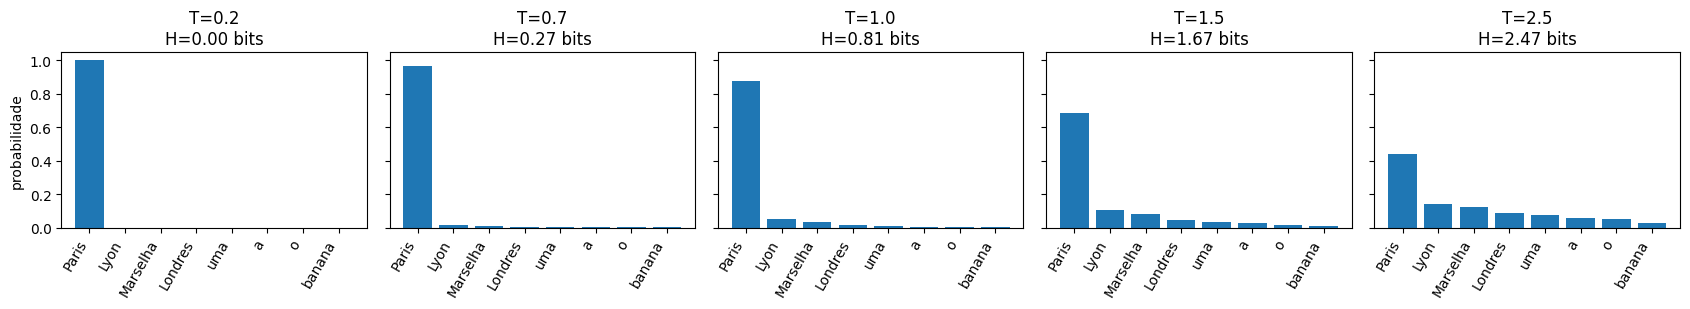

In [6]:
temps = [0.2, 0.7, 1.0, 1.5, 2.5]
fig, axes = plt.subplots(1, len(temps), figsize=(17, 3.2), sharey=True)
for ax, T in zip(axes, temps):
    p = softmax(logits, T)
    ax.bar(range(len(vocab)), p)
    ax.set_xticks(range(len(vocab)))
    ax.set_xticklabels(vocab, rotation=60, ha="right")
    ax.set_title(f"T={T}\nH={entropy(p):.2f} bits")
axes[0].set_ylabel("probabilidade")
plt.tight_layout()
plt.show()

**Leitura:**

- Com $T=0.2$, "Paris" domina quase totalmente (comportamento próximo do *greedy*).
- Com $T=2.5$, a distribuição fica bem mais plana e até "banana" passa a ter uma chance perceptível (cerca de 3%), o que seria muito raro com $T=0.2$.
- $T$ **não cria conhecimento**: só redistribui a massa que o modelo já atribuiu. Se o modelo "sabe" a resposta, $T$ baixa a torna mais estável. Se não sabe, $T$ baixa só deixa o erro mais consistente.

### 1.4 `top_k` e `top_p`: cortando a cauda

Mesmo com $T=1$, a **cauda longa** (tokens improváveis, mas muitos) soma uma massa não desprezível. Em vocabulários reais de 100 mil tokens, sortear da cauda de vez em quando é a origem de muitos "tropeços" em textos longos. `top_k` e `top_p` cortam essa cauda.

In [7]:
configs = {
    "T=1.0 (puro)":        softmax(logits, 1.0),
    "T=0.7":               softmax(logits, 0.7),
    "T=2.0":               softmax(logits, 2.0),
    "T=2.0 + top_p=0.9":   top_p_probs(softmax(logits, 2.0), 0.9),
    "T=1.0 + top_k=3":     top_k_probs(softmax(logits, 1.0), 3),
    "T=1.0 + top_p=0.9":   top_p_probs(softmax(logits, 1.0), 0.9),
}
rows = []
for name, p in configs.items():
    rows.append({
        "config": name,
        "P(Paris)": p[0],
        "massa fora do top-3": p[3:].sum(),
        "tokens ativos": int((p > 0).sum()),
        "entropia (bits)": entropy(p),
    })
display(pd.DataFrame(rows).round(3))

rng = np.random.default_rng(0)
for name in ["T=2.0", "T=2.0 + top_p=0.9"]:
    amostra = rng.choice(vocab, size=15, p=configs[name])
    print(f"{name:20s}->", " ".join(amostra))

,config,P(Paris),massa fora do top-3,tokens ativos,entropia (bits)
0,T=1.0 (puro),0.875,0.036,8,0.807
1,T=0.7,0.966,0.006,8,0.271
2,T=2.0,0.536,0.224,8,2.185
3,T=2.0 + top_p=0.9,0.592,0.143,5,1.761
4,T=1.0 + top_k=3,0.908,0.000,3,0.533
5,T=1.0 + top_p=0.9,0.943,0.000,2,0.317


T=2.0               -> Lyon Paris Paris Paris Londres a Lyon Marselha Lyon a Londres Paris uma Paris Marselha
T=2.0 + top_p=0.9   -> Paris Londres Paris Paris Paris Paris Paris Lyon Lyon Lyon Paris uma uma Lyon Lyon


**Pontos de rigor:**

- `top_p` é **adaptativo**: quando o modelo está confiante, o núcleo tem 1 ou 2 tokens. Quando está incerto, tem muitos. `top_k` corta sempre $k$ tokens, mesmo que 3 deles tenham probabilidade ínfima.
- **Boa prática** (inclusive recomendada em documentações): ajustar **um** dos dois (`temperature` *ou* `top_p`) por vez. Mexer nos dois ao mesmo tempo torna o efeito difícil de interpretar.
- $T=0$ é tratado como ***greedy decoding*** (argmax), porque dividir por zero é indefinido. Mesmo assim, em APIs hospedadas o resultado pode **não ser 100% determinístico** (por exemplo, por diferenças numéricas em GPUs e *batching*). Não assuma determinismo absoluto.

### 1.5 Penalidades de repetição

Existem duas famílias, e **elas não são equivalentes**:

- **`frequency_penalty` / `presence_penalty`** (estilo OpenAI), **aditivas**: subtraem do logit do token $j$ um valor proporcional a quantas vezes ele já apareceu ($c_j$):
  $$z_j' = z_j - c_j \cdot \alpha_{freq} - \mathbb{1}[c_j>0]\cdot\alpha_{pres}$$
- **`repetition_penalty`** (estilo Hugging Face, de Keskar et al., CTRL, arXiv 1909.05858), **multiplicativa**: para tokens já vistos (no prompt **e** na geração), divide o logit por $\theta$ se for positivo e multiplica por $\theta$ se for negativo.

In [8]:
def openai_penalties(z, counts, freq=0.0, pres=0.0):
    return z - counts * freq - (counts > 0) * pres


def hf_repetition_penalty(z, seen, theta):
    z = z.copy()
    z[seen] = np.where(z[seen] > 0, z[seen] / theta, z[seen] * theta)
    return z


counts = np.zeros(len(vocab)); counts[0] = 3        # "Paris" já foi gerado 3 vezes
seen = counts > 0

z_freq = openai_penalties(logits, counts, freq=0.5)
z_rep  = hf_repetition_penalty(logits, seen, theta=1.3)

df_pen = pd.DataFrame({
    "token": vocab,
    "p original": softmax(logits),
    "p c/ frequency_penalty=0.5": softmax(z_freq),
    "p c/ repetition_penalty=1.3": softmax(z_rep),
}).round(3)
display(df_pen)

,token,p original,p c/ frequency_penalty=0.5,p c/ repetition_penalty=1.3
0,Paris,0.875,0.610,0.637
1,Lyon,0.053,0.166,0.155
2,Marselha,0.036,0.111,0.104
3,Londres,0.016,0.050,0.047
4,uma,0.010,0.030,0.028
5,a,0.006,0.018,0.017
6,o,0.004,0.011,0.010
7,banana,0.001,0.002,0.002


**Atenção prática:** penalizar repetição é uma faca de dois gumes. Em **JSON**, **código** ou qualquer texto que *precise* repetir tokens (chaves, aspas, nomes de campos), penalidades altas podem **degradar a qualidade**. Para saídas estruturadas, evite penalidades fortes 

---
## Parte 2 · Tokens e `max_tokens`

### 2.1 Tokens

O modelo não enxerga caracteres nem palavras, e sim **tokens** (pedaços de palavras definidos por um tokenizer, como BPE). Isso importa porque **`max_tokens`, janela de contexto, custo e latência** são todos medidos em tokens, e o português costuma gerar mais tokens por palavra do que o inglês.

In [9]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODELS["hf_local"])   # só o tokenizer, download pequeno

texto = "Tokenização em português: anticonstitucionalissimamente é uma palavra rara."
ids = tok.encode(texto)
print(f"{len(texto.split())} palavras -> {len(ids)} tokens")
print([tok.decode([i]) for i in ids])

config.json:   0%|          | 0.00/802 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/17.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.25M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

8 palavras -> 21 tokens
['Token', 'ização', ' em', ' port', 'ugu', 'ês', ':', ' ant', 'icon', 'stit', 'uc', 'ional', 'iss', 'im', 'amente', ' é', ' uma', ' palavra', ' r', 'ara', '.']


### 2.2 `max_tokens` (e uma prévia da janela de contexto)

- **`max_tokens`** (`max_new_tokens` no `transformers`) é um **teto duro** para o tamanho da *resposta*. Não é um alvo: o modelo não "planeja" terminar a tempo, e a resposta simplesmente **é cortada** (veremos `finish_reason="length"` na Parte 5).

> **Prévia: janela de contexto.** Todo modelo tem um limite de tokens por chamada que soma **entrada e saída**: `prompt + histórico + resposta ≤ janela do modelo`. Como a API não guarda estado (Parte 4), o histórico inteiro é reenviado a cada turno e disputa espaço com a resposta. Medir e gerenciar esse limite é o tema do **Capítulo 2** (gerenciamento de contexto).

### 2.3 Nota rápida sobre chat templates

APIs de chat recebem uma lista de mensagens com papéis, mas o modelo lê uma sequência linear de tokens; quem faz a conversão é o **chat template**, específico de cada família de modelo. O ponto que importa para este notebook: **em APIs (Groq, HF Inference) o template é aplicado no servidor**; em `hf_local` ele é aplicado do seu lado pela biblioteca. A anatomia do template (tokens de controle, `apply_chat_template`, `add_generation_prompt`) está demonstrada no notebook *Formatos de Entrada e Saída*, Seção 2.

---
## Parte 3 · Conectando provedores com LangChain

Vamos criar uma **fábrica** `make_llm(...)` que devolve um *chat model* do LangChain, com a mesma interface (`.invoke(messages)`), seja qual for o provedor. Assim todos os experimentos seguintes rodam em qualquer um deles. O mapeamento dos parâmetros muda por provedor:

| Conceito | `transformers` (local) | HF Inference via `ChatHuggingFace` (rota *chat completion*) | Groq (API estilo OpenAI) | Ollama |
|---|---|---|---|---|
| temperatura | `temperature` | `temperature` | `temperature` (`0` vira `1e-8`) | `temperature` |
| nucleus | `top_p` | `top_p` (via `model_kwargs`) | `top_p` | `top_p` |
| top-k | `top_k` | não existe nessa rota | não documentado | `top_k` |
| teto de saída | `max_new_tokens` | `max_tokens` | `max_tokens` | `num_predict` |
| repetição | `repetition_penalty` (multiplicativa) | `frequency_penalty` / `presence_penalty` (aditivas; suporte depende do provider) | `frequency_penalty` / `presence_penalty`: **aceitos, mas a doc da Groq diz que nenhum modelo suporta ainda** | `repeat_penalty` (multiplicativa) |
| amostrar ou greedy | `do_sample` | implícito (`temperature`) | implícito (`temperature`) | implícito |
| semente | `set_seed(...)` | `seed` (via `model_kwargs`) | `seed` (melhor esforço) | `seed` |

**Quatro armadilhas silenciosas** (verificadas no código de `langchain-groq` 1.1.3 e `langchain-huggingface` 1.2.3):

1. **`do_sample` no `transformers`:** se `do_sample=False`, `temperature`, `top_p` e `top_k` são ignorados (decodificação *greedy*). Por isso a fábrica liga `do_sample` sempre que `temperature > 0`.
2. **`ChatHuggingFace` + endpoint:** o wrapper conversa com a API de *chat completion* e só repassa `temperature`, `max_tokens`, `stop` e o conteúdo de `model_kwargs`. `top_p`, `seed` e `repetition_penalty` configurados no `HuggingFaceEndpoint` **somem sem erro**. Por isso eles vão em `model_kwargs` do `ChatHuggingFace`.
3. **`HuggingFacePipeline`:** `pipeline_kwargs` passados no **construtor** não são usados na geração, só os passados em cada chamada. Sem isso, o modelo local ignora `temperature`/`max_new_tokens` e devolve **o prompt inteiro junto com a resposta** (`return_full_text=True`). A fábrica resolve com `.bind(pipeline_kwargs=...)`.
4. **Defaults escondidos do modelo (local):** todo parâmetro que você **não** passa vem do `generation_config.json` do modelo. No Qwen2.5-0.5B-Instruct ele traz `do_sample=True`, `temperature=0.7`, `top_p=0.8`, `top_k=20` e `repetition_penalty=1.1`. Ou seja, “`top_p=1.0`” sem `top_k=0` ainda corta a cauda em 20 tokens. Em APIs hospedadas o equivalente são os defaults do provedor, que você também não vê.

> **Moral:** parâmetro que não chega à API **não dá erro**, só não faz efeito. Antes de concluir que "o parâmetro não funciona", confira o que foi de fato enviado (logs ou *tracing*, tema do Capítulo 5).

> **Segurança:** nunca escreva chaves no código nem as publique em repositórios. Aqui usamos variáveis de ambiente / `getpass`.


In [11]:
# ---- Chaves: Secrets do Kaggle -> Secrets do Colab -> variável de ambiente 
def secrets(nome):
    """Procura o segredo no ambiente, depois nos Secrets do Kaggle e do Colab. Nunca imprime o valor."""
    valor = os.environ.get(nome)
    if not valor:
        try:
            from kaggle_secrets import UserSecretsClient          # Kaggle: Add-ons -> Secrets, marque "Attached"
            valor = UserSecretsClient().get_secret(nome)
        except Exception:
            pass
    if not valor:
        try:
            from google.colab import userdata                    # Colab: ícone de chave (Secrets) + acesso ao notebook
            valor = userdata.get(nome)
        except Exception:
            pass
    if valor:
        os.environ[nome] = valor.strip()
    return bool(valor)


secrets("HF_TOKEN")   # opcional: só é obrigatório para modelos gated (ex.: Llama)
if PROVIDER == "groq" and not secrets("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("GROQ_API_KEY: ")
if PROVIDER == "hf_api" and not (secrets("HUGGINGFACEHUB_API_TOKEN") or os.environ.get("HF_TOKEN")):
    os.environ["HUGGINGFACEHUB_API_TOKEN"] = getpass.getpass("HUGGINGFACEHUB_API_TOKEN: ")
if PROVIDER == "hf_local":                                   # falha cedo, com mensagem clara, se o modelo for gated
    from huggingface_hub import hf_hub_download
    try:
        hf_hub_download(MODELS["hf_local"], "config.json", token=os.environ.get("HF_TOKEN"))
        print("Acesso ao modelo local OK:", MODELS["hf_local"])
    except Exception as e:
        raise RuntimeError(f"Sem acesso a {MODELS['hf_local']}. Se o modelo for gated (ex.: Llama), aceite a licença "
                           "na página do modelo no Hub e configure o secret HF_TOKEN.") from e


_LOCAL_PIPE = {}   # cache: carregar o modelo local a cada chamada seria lentíssimo


def make_llm(provider=None, temperature=0.7, top_p=None, max_tokens=256, model=None, **extra):
    """Cria um chat model do LangChain com os parâmetros pedidos.

    extra: parâmetros específicos (ex.: frequency_penalty, repetition_penalty, top_k, seed).
    Lição desta função: a interface é a mesma, mas CADA integração encaminha os parâmetros
    de um jeito. Parâmetro que não chega à API é ignorado em silêncio (ver Parte 3).
    """
    provider = provider or PROVIDER
    modelo = model or MODELS[provider]        # model=... permite comparar modelos do mesmo provedor (5.6)
    extra = dict(extra)

    if provider == "groq":
        from langchain_groq import ChatGroq
        mk = dict(extra)                       # top_p, seed e penalidades não são campos do ChatGroq -> model_kwargs
        if top_p is not None:
            mk["top_p"] = top_p
        return ChatGroq(model=modelo, temperature=temperature,
                        max_tokens=max_tokens, model_kwargs=mk,
                        reasoning_effort=GROQ_REASONING.get(modelo),
                        max_retries=6)         # free tier: erro 429 por tokens/min é comum; o SDK espera e tenta de novo

    if provider == "hf_api":
        from langchain_huggingface import HuggingFaceEndpoint, ChatHuggingFace
        # ChatHuggingFace usa a API de *chat completion* (estilo OpenAI) e só repassa temperature,
        # max_tokens, stop e o que estiver em SEU model_kwargs. top_p/seed passados ao
        # HuggingFaceEndpoint seriam descartados em silêncio -> vão em model_kwargs.
        if "repetition_penalty" in extra:
            raise ValueError("A rota de chat da HF não tem repetition_penalty; use frequency_penalty/presence_penalty.")
        mk = {k: v for k, v in extra.items() if v is not None}   # seed, frequency_penalty, presence_penalty...
        if top_p is not None:
            mk["top_p"] = top_p
        endpoint = HuggingFaceEndpoint(
            repo_id=modelo,
            task="text-generation",
            max_new_tokens=max_tokens,
            temperature=max(temperature, 0.01),        # alguns backends exigem temperature > 0
            huggingfacehub_api_token=os.environ.get("HUGGINGFACEHUB_API_TOKEN") or os.environ.get("HF_TOKEN"),
        )
        return ChatHuggingFace(llm=endpoint, model_kwargs=mk)

    if provider == "hf_local":
        from transformers import pipeline, set_seed
        from langchain_huggingface import HuggingFacePipeline, ChatHuggingFace
        seed = extra.pop("seed", None)
        if seed is not None:
            set_seed(seed)
        if modelo not in _LOCAL_PIPE:
            _LOCAL_PIPE[modelo] = pipeline("text-generation", model=modelo,
                                           device_map="auto")   # usa a GPU do Kaggle/Colab se houver; senão, CPU
        pk = {"max_new_tokens": max_tokens, "return_full_text": False, "do_sample": temperature > 0}
        if temperature > 0:
            pk["temperature"] = temperature
            if top_p is not None:
                pk["top_p"] = top_p
            if extra.get("top_k") is not None:
                pk["top_k"] = extra["top_k"]
        if extra.get("repetition_penalty"):
            pk["repetition_penalty"] = extra["repetition_penalty"]
        llm = HuggingFacePipeline(pipeline=_LOCAL_PIPE[modelo], model_id=modelo)
        # ATENÇÃO: pipeline_kwargs passados no CONSTRUTOR do HuggingFacePipeline não chegam à geração
        # (só os passados na chamada). Com .bind() eles viajam em toda chamada.
        # O que você NÃO passar vem do generation_config.json do modelo (ver Parte 3, armadilha 4).
        # Limitação: nesta rota, `stop` não é aplicado.
        return ChatHuggingFace(llm=llm, model_id=modelo).bind(pipeline_kwargs=pk)

    if provider == "ollama":
        from langchain_ollama import ChatOllama
        # Ollama aplica temperature/top_p no modelo local. Nem todo parâmetro
        # tem suporte uniforme entre modelos; consulte a documentação do Ollama.
        opts = {"temperature": temperature, "num_predict": max_tokens}
        if top_p is not None:
            opts["top_p"] = top_p
        if "seed" in extra and extra["seed"] is not None:
            opts["seed"] = extra.pop("seed")
        if "repetition_penalty" in extra:
            opts["repeat_penalty"] = extra.pop("repetition_penalty")
        opts.update(extra)
        return ChatOllama(model=modelo, **opts)

    raise ValueError(f"provider desconhecido: {provider}")


def as_text(msg):
    """Extrai texto de uma AIMessage (o content pode ser str ou lista de blocos)."""
    c = msg.content
    if not isinstance(c, str):
        c = "".join(b.get("text", "") if isinstance(b, dict) else str(b) for b in c)
    return re.sub(r"<think>.*?</think>\s*", "", c, flags=re.S)   # alguns modelos de raciocínio devolvem o "pensamento" no texto


def ask(llm, messages, **kw):
    """invoke + pausa para respeitar rate limit."""
    resp = llm.invoke(messages, **kw)
    time.sleep(THROTTLE[PROVIDER])
    return resp


from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

llm = make_llm(temperature=0.0, max_tokens=60)
resp = ask(llm, [HumanMessage("Diga olá em uma frase.")])
print(as_text(resp))

Acesso ao modelo local OK: microsoft/phi-4


model.safetensors.index.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/243 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

Olá! Como posso ajudar você hoje?


---
## Parte 4 · Primeira chamada e conversa sem estado

O LangChain representa os papéis como `SystemMessage`, `HumanMessage` (user) e `AIMessage` (assistant). O que cada papel faz, few-shot com turnos `assistant` e a separação de privilégios entre eles estão no notebook *Formatos de Entrada e Saída*. Aqui vamos mostrar apenas a chamada do modelo

1. **Anatomia da resposta:** além do texto, a resposta traz `response_metadata` (ex.: `finish_reason`) e `usage_metadata` (tokens de entrada/saída), que usaremos na Parte 5 para medir truncamento, latência e custo.
2. **A API é sem estado (*stateless*)**: o modelo **não lembra** de chamadas anteriores. Quem "tem memória" é o seu código, que reenvia o histórico a cada chamada. Por isso o histórico cresce e consome contexto (tema do Capítulo 2).

In [12]:
llm = make_llm(temperature=0.0, max_tokens=150)

# 1) Primeira chamada: texto + metadados
msgs = [
    SystemMessage("Você é um professor de computação. Responda em no máximo 2 frases."),
    HumanMessage("O que é um token em um LLM?"),
]
resp = ask(llm, msgs)
print(as_text(resp))
print("\nresponse_metadata:", resp.response_metadata)
print("usage_metadata   :", resp.usage_metadata)

Em um modelo de linguagem grande (LLM), um token é uma unidade básica de entrada ou saída, que pode ser uma palavra, parte de uma palavra, ou um caractere, dependendo do tokenizador usado. O tokenizador divide o texto em tokens que o modelo pode processar, permitindo que ele entenda e gere linguagem de forma eficaz.

response_metadata: {}
usage_metadata   : None


In [13]:
# 2) Sem estado: o modelo não lembra se você não reenviar o histórico
r1 = ask(llm, [HumanMessage("Meu nome é Ana. Guarde isso.")])
r2 = ask(llm, [HumanMessage("Qual é o meu nome?")])                       # sem histórico
r3 = ask(llm, [HumanMessage("Meu nome é Ana. Guarde isso."), r1,
               HumanMessage("Qual é o meu nome?")])                       # com histórico
print("\nsem histórico:", as_text(r2).strip()[:150])
print("com histórico :", as_text(r3).strip()[:150])

sem histórico: Desculpe, mas não posso saber seu nome, pois não tenho acesso a informações pessoais sobre usuários. Se você quiser que eu te ajude com algo, sinta-se
com histórico : Seu nome é Ana. Você mencionou isso no início de nossa conversa. Se precisar de mais alguma coisa, estou à disposição!


---
## Parte 5 · Experimentos com parâmetros

Como a saída é **estocástica**, **uma chamada não prova nada**. Vamos repetir cada configuração $k$ vezes e olhar a **diversidade** das respostas. Ajuste `K` conforme seu limite de requisições (menos chamadas = mais rápido, porém mais ruído).

### 5.1 `temperature`: tarefa criativa vs. tarefa factual

Hipótese: em uma pergunta com **uma resposta clara**, a temperatura quase não deve importar (o modelo é confiante). Em uma tarefa **aberta**, a diversidade deve crescer com $T$.

In [14]:
K = 5


def run_samples(messages, k, **params):
    llm = make_llm(**params)
    return [as_text(ask(llm, messages)).strip() for _ in range(k)]


def sweep(prompt, name, values, k=K, **fixed):
    """Varre um parâmetro e resume a diversidade das respostas."""
    rows = []
    for v in values:
        outs = run_samples([HumanMessage(prompt)], k, **{**fixed, name: v})
        rows.append({
            name: v,
            "respostas distintas": f"{len(set(outs))}/{k}",
            "amostras": " | ".join(o.replace("\n", " ")[:45] for o in outs),
        })
    return pd.DataFrame(rows)


print("FACTUAL")
display(sweep("Qual é a capital da Austrália? Responda com uma palavra.",
              "temperature", [0.0, 0.5, 1.0], max_tokens=10))

print("CRIATIVA")
display(sweep("Invente um nome para uma cafeteria que só serve café brasileiro. Responda apenas com o nome.",
              "temperature", [0.0, 0.5, 1.0], max_tokens=20))

FACTUAL


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,temperature,respostas distintas,amostras
0,0.0,1/5,Canberra | Canberra | Canberra | Canberra | Canberra
1,0.5,1/5,Canberra | Canberra | Canberra | Canberra | Canberra
2,1.0,2/5,Canberra | Canberra | Canoberra | Canberra | Canberra


CRIATIVA


,temperature,respostas distintas,amostras
0,0.0,1/5,Café Brasilisimo | Café Brasilisimo | Café Brasilisimo | Café Brasilisimo | Café Brasilisimo
1,0.5,4/5,Café Brasilisimo | Café Brasilisimo | Café Brasilisso | Café Brasilisca | Café Brasilisca.
2,1.0,5/5,Café Brasiliscares. | Sabor Brasil Café | Café Brasilisênio | Café Brasilisimo | Sabor Brasil Cafés


**O que observar:**

- Em $T=0$ esperamos respostas (quase) idênticas.
- Na tarefa factual, a diversidade deve ficar baixa mesmo com $T=1$. Se o modelo for pequeno e inseguro, pode haver variação (e erros).
- Na tarefa criativa, a diversidade sobe com $T$.

### 5.2 `top_p` com temperatura fixa

Fixamos $T=1$ e variamos `top_p`. Menor `top_p` = núcleo menor = menos diversidade.

In [15]:
display(sweep("Invente um nome para uma cafeteria que só serve café brasileiro. Responda apenas com o nome.",
              "top_p", [1.0, 0.9, 0.5, 0.1], temperature=1.0, max_tokens=20))

,top_p,respostas distintas,amostras
0,1.0,4/5,Café Brasilíssimo | Café Brasilisca | Café Brasilidade | Café Brasilisso! | Café Brasilíssimo
1,0.9,5/5,"""Arábica Brasil Café"" | Café Brasilisimo. | Café Brasilíssima | Café Brasilíssimo | Brasil Caféteria"
2,0.5,2/5,Café Brasilisca | Café Brasilisimo | Café Brasilisimo | Café Brasilisca | Café Brasilisca
3,0.1,1/5,Café Brasilisimo | Café Brasilisimo | Café Brasilisimo | Café Brasilisimo | Café Brasilisimo


### 5.2b Diversidade medida: *distinct-n* e `top_k` num modelo real

"Respostas distintas" (5.1) só diz **se** o texto mudou, não **quanto**. A métrica *distinct-n* (Li et al., 2016) mede a fração de n-gramas únicos somando as $K$ respostas:

$$\text{distinct-}n = \frac{\#\ n\text{-gramas únicos}}{\#\ n\text{-gramas totais}}$$

- **Piso ≈ $1/K$:** as $K$ respostas são idênticas. **Teto 1.0:** nenhum n-grama se repete.
- *distinct-1* (palavras) capta troca de vocabulário. *distinct-2* (pares de palavras) capta troca de estrutura.

**Hipóteses, ligadas à Parte 1:**

1. **H1.** Com $T=0$, as $K$ respostas são iguais (*greedy*).
2. **H2.** *distinct-n* cresce com $T$, como a entropia na 1.3.
3. **H3.** `top_k=1` reproduz o *greedy* mesmo com $T=1$. É uma checagem de sanidade: se falhar, o parâmetro não chegou ao modelo (armadilhas da Parte 3).
4. **H4.** Com $T=1$, `top_k` pequeno limita a diversidade. Mas, se a massa já está concentrada em poucos tokens, `top_k=5` e `top_k=50` ficam parecidos: é o argumento da 1.4 de que o corte por contagem ignora a forma da distribuição.

> **Provedor:** H1 e H2 rodam em qualquer provedor. H3 e H4 exigem `top_k`, que só existe em `hf_local` e `ollama` (a Groq não documenta o parâmetro e a rota de chat da HF não o tem). No Kaggle/Colab, `PROVIDER="hf_local"` funciona: o Qwen2.5-0.5B cabe na CPU. Em outro provedor, a célula pula H3/H4 com aviso.

In [16]:
def distinct_n(textos, n=2):
    """Fração de n-gramas únicos sobre o total, somando todas as respostas.
    ≈1/K = as K respostas são idênticas; 1.0 = nenhum n-grama se repete."""
    ngramas = []
    for t in textos:
        w = re.findall(r"\w+", t.lower())
        ngramas += [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
    return len(set(ngramas)) / len(ngramas) if ngramas else float("nan")


def diversidade(outs):
    """Resumo de diversidade de uma lista de respostas."""
    return {"distinct-1": distinct_n(outs, 1), "distinct-2": distinct_n(outs, 2),
            "respostas distintas": len(set(outs)),
            "exemplos": " | ".join(o.replace("\n", " ")[:30] for o in outs[:4])}


# Checagens offline da métrica
assert distinct_n(["café do brasil"] * 4) == 1 / 4              # 4 respostas iguais -> piso 1/K
assert distinct_n(["café do brasil", "grão de ouro"]) == 1.0    # nada se repete -> teto
print("distinct_n OK")

distinct_n OK


,temperature,distinct-1,distinct-2,respostas distintas,exemplos
0,0.0,0.125,0.125,1,Café Brasilisimo | Café Brasilisimo | Café Brasilisimo | Café Brasilisimo
1,0.3,0.188,0.250,2,Café Brasilisca | Café Brasilisimo | Café Brasilisimo | Café Brasilisca
2,0.7,0.474,0.727,5,Café Brasilis Verdes Campos | Café Brasilisca | Café Brasilisca | Café Brasilíssimo
3,1.0,0.600,1.000,8,Expressão Carioca Café | Brasilíssimo Café | Café Brasilíssimo | Café Brasilisense
4,1.3,0.522,0.867,8,BrasilEspresso Café | Cafés do Brasil Saborífico | Café ArcoBrasileiro | Café Brasilisca


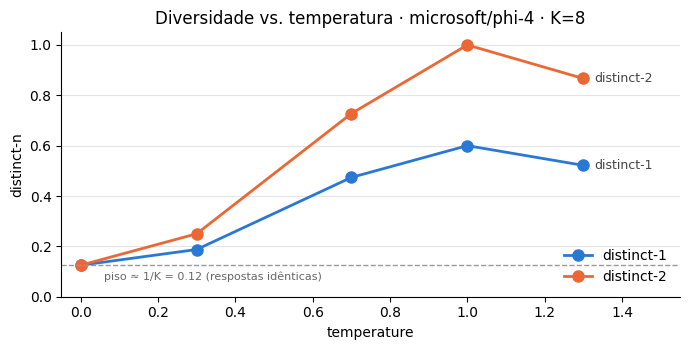

distinct-2: 0.12 (T=0.0) -> 0.87 (T=1.3) | correlação de Spearman com T: +0.90
H1 (T=0 -> respostas iguais): confirmada
H2 (diversidade cresce com T): confirmada


In [17]:
PROMPT_CRIATIVO = "Invente um nome para uma cafeteria que só serve café brasileiro. Responda apenas com o nome."
K_DIV = 8                                   # amostras por ponto; com menos, o ruído domina a tendência
TEMPS_DIV = [0.0, 0.3, 0.7, 1.0, 1.3]

df_div = pd.DataFrame([
    {"temperature": T, **diversidade(run_samples([HumanMessage(PROMPT_CRIATIVO)], K_DIV, temperature=T, max_tokens=20))}
    for T in TEMPS_DIV
])
display(df_div.round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
for col, cor in [("distinct-1", "#2a78d6"), ("distinct-2", "#eb6834")]:
    ax.plot(df_div["temperature"], df_div[col], marker="o", lw=2, ms=8, color=cor, label=col)
    ultimo = df_div[col].iloc[-1]
    if pd.notna(ultimo):
        ax.annotate(col, (TEMPS_DIV[-1], ultimo), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9, color="#444")
ax.axhline(1 / K_DIV, ls="--", lw=1, color="#999")
ax.text(TEMPS_DIV[0] + 0.06, 1 / K_DIV - 0.06, f"piso ≈ 1/K = {1 / K_DIV:.2f} (respostas idênticas)", fontsize=8, color="#666")
ax.set(xlabel="temperature", ylabel="distinct-n", ylim=(0, 1.05), xlim=(-0.05, TEMPS_DIV[-1] + 0.25),
       title=f"Diversidade vs. temperatura · {MODELS[PROVIDER]} · K={K_DIV}")
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# Leitura automática (os números vêm da sua execução, não de um gabarito)
iguais_T0 = df_div.loc[0, "respostas distintas"] == 1
par = df_div[["temperature", "distinct-2"]].dropna()
rho = par["temperature"].rank().corr(par["distinct-2"].rank()) if len(par) >= 3 else float("nan")
print(f"distinct-2: {df_div['distinct-2'].iloc[0]:.2f} (T={TEMPS_DIV[0]}) -> {df_div['distinct-2'].iloc[-1]:.2f} "
      f"(T={TEMPS_DIV[-1]}) | correlação de Spearman com T: {rho:+.2f}")
print("H1 (T=0 -> respostas iguais):", "confirmada" if iguais_T0 else
      f"NÃO confirmada ({df_div.loc[0, 'respostas distintas']} respostas distintas): APIs não são 100% determinísticas (1.4)")
print("H2 (diversidade cresce com T):", "confirmada" if rho > 0.8 else
      "parcial ou não confirmada; aumente K_DIV antes de concluir")

In [18]:
if PROVIDER in ("hf_local", "ollama"):
    TOP_KS = [1, 5, 50]
    df_topk = pd.DataFrame([
        {"top_k": k, **diversidade(run_samples([HumanMessage(PROMPT_CRIATIVO)], K_DIV,
                                               temperature=1.0, max_tokens=20, top_k=k))}
        for k in TOP_KS
    ])
    display(df_topk.round(3))

    print("H3 (top_k=1 = greedy):", "confirmada" if df_topk.loc[0, "respostas distintas"] == 1 else
          "NÃO confirmada: confira se top_k chegou ao modelo (Parte 3)")
    d5, d50 = df_topk.loc[1, "distinct-2"], df_topk.loc[2, "distinct-2"]
    if pd.isna(d5) or pd.isna(d50):
        print("H4: respostas curtas demais para distinct-2; compare distinct-1 na tabela.")
    elif d50 - d5 < 0.10:
        print(f"H4: top_k=5 ({d5:.2f}) ≈ top_k=50 ({d50:.2f}): a massa já está nos primeiros tokens, "
              "então cortar em 5 ou em 50 dá quase no mesmo (o top_k ignora a forma da distribuição, 1.4).")
    else:
        print(f"H4: top_k=5 ({d5:.2f}) < top_k=50 ({d50:.2f}): o corte em 5 tokens remove diversidade real.")
else:
    print(f"H3/H4 puladas: '{PROVIDER}' não expõe top_k. Rode com PROVIDER='hf_local' (Kaggle/Colab) ou 'ollama'.")

,top_k,distinct-1,distinct-2,respostas distintas,exemplos
0,1,0.125,0.125,1,Café Brasilisimo | Café Brasilisimo | Café Brasilisimo | Café Brasilisimo
1,5,0.353,0.556,5,Café Brasilisca | Café Brasilisimo! | Arábica Brasilis Café | Café Brasilisimo
2,50,0.652,0.933,8,"""Café Brasilíssimo"" | Brasilíssimo Café | Brasilzinho Café Arteano. | SaborCafé Brasilense"


H3 (top_k=1 = greedy): confirmada
H4: top_k=5 (0.56) < top_k=50 (0.93): o corte em 5 tokens remove diversidade real.


**Como ler e limites da medição:**

- *distinct-n* é uma medida **léxica**: "Café Raiz" e "Raiz do Café" contam como diferentes, mas um sinônimo perfeito também conta. Ela não mede diversidade de **ideias**.
- A métrica depende de $K$ e do tamanho das respostas. Compare só pontos com o mesmo $K$ e o mesmo prompt. Com $K=8$, diferenças pequenas (< 0,1) estão dentro do ruído.
- **Para agentes:** diversidade é inimiga nos passos de **controle** (escolher ferramenta, extrair um campo, decidir o próximo passo) e aliada nos passos de **geração de alternativas** (brainstorm, várias tentativas com votação, como em *self-consistency*). Regra prática: $T$ baixa no controle, $T$ alta só onde a variação é o objetivo.

### 5.3 `max_tokens`, `finish_reason` e *stop sequences*

`finish_reason` diz **por que** a geração parou: `"stop"` (o modelo terminou, ou bateu em uma *stop sequence*) ou `"length"` (**cortado** por `max_tokens`). Em produção, checar isso evita tratar uma resposta truncada como completa, e é crítico em JSON, que truncado vira inválido (saídas estruturadas: notebook *Formatos de Entrada e Saída*, Parte 2).

> Com `PROVIDER="hf_local"` o `HuggingFacePipeline` não informa `finish_reason` (aparece `n/d`) e não aplica `stop`. Outra diferença de suporte entre provedores.

In [19]:
prompt_longo = "Explique o que é um transformer em três parágrafos."
rows = []
for mt in [20, 60, 250]:
    r = ask(make_llm(temperature=0.0, max_tokens=mt), [HumanMessage(prompt_longo)])
    rows.append({
        "max_tokens": mt,
        "finish_reason": r.response_metadata.get("finish_reason", "n/d"),
        "tokens de saída": (r.usage_metadata or {}).get("output_tokens", "n/d"),
        "final do texto": "..." + as_text(r)[-60:].replace("\n", " "),
    })
display(pd.DataFrame(rows))

,max_tokens,finish_reason,tokens de saída,final do texto
0,20,n/d,n/d,...rofundo que revolucionaram o campo da processamento de lingu
1,60,n/d,n/d,...o de dados. Eles foram introduzidos em um artigo de 2017 por
2,250,n/d,n/d,...ações para gerar a saída. Ambos os componentes são compostos


In [20]:
# Stop sequence: a geração é interrompida ao produzir a sequência (que NÃO aparece na saída)
r = ask(make_llm(temperature=0.0, max_tokens=100),
        [HumanMessage("Liste 5 frutas, numeradas de 1 a 5, uma por linha.")],
        stop=["3."])
print(as_text(r))
print("finish_reason:", r.response_metadata.get("finish_reason", "n/d"))

1. Maçã  
2. Banana  
3. Laranja  
4. Morango  
5. Uva
finish_reason: n/d


### 5.4 Penalidades de repetição

Medimos a **razão tipo/token (TTR)**: palavras distintas ÷ total de palavras. TTR mais alta = menos repetição. É uma métrica **grosseira** (depende do tamanho do texto), mas suficiente para ver a tendência. Cada provedor usa um parâmetro diferente (ver tabela da Parte 3). **Alguns provedores/modelos podem rejeitar ou ignorar** certas penalidades. Por isso o código captura o erro em vez de quebrar. Isso também é uma lição: *a interface é parecida, mas o suporte varia*.

> **Groq:** a referência da API informa que `frequency_penalty` e `presence_penalty` **ainda não são suportados por nenhum modelo**: são aceitos sem erro, mas não fazem efeito. Com `PROVIDER="groq"`, espere diferenças de TTR **dentro do ruído**. Esse é o resultado correto, não um bug. Para ver o efeito real da penalidade, rode esta seção com `hf_local` ou `ollama`.

In [21]:
PEN = {
    "groq":     ("frequency_penalty", [0.0, 0.8, 1.5]),
    "hf_api":   ("frequency_penalty", [0.0, 0.8, 1.5]),     # rota de chat da HF: penalidade aditiva
    "hf_local": ("repetition_penalty", [1.0, 1.2, 1.5]),
    "ollama":   ("repeat_penalty", [1.0, 1.2, 1.5]),
}
pen_name, pen_vals = PEN[PROVIDER]


def ttr(text):
    w = re.findall(r"\w+", text.lower())
    return len(set(w)) / max(len(w), 1)


rows = []
for v in pen_vals:
    try:
        outs = run_samples([HumanMessage("Escreva um texto de cerca de 80 palavras sobre o mar.")],
                           3, temperature=0.7, max_tokens=200, **{pen_name: v})
        rows.append({pen_name: v, "TTR médio": round(float(np.mean([ttr(o) for o in outs])), 3),
                     "palavras (média)": round(float(np.mean([len(o.split()) for o in outs])), 1)})
    except Exception as e:
        rows.append({pen_name: v, "TTR médio": None, "erro": str(e)[:150]})
display(pd.DataFrame(rows))

,repetition_penalty,TTR médio,palavras (média)
0,1.0,0.731,96.3
1,1.2,0.919,96.0
2,1.5,0.981,101.0


### 5.5 `seed` e reprodutibilidade

Fixar `seed` torna a amostragem **reprodutível em princípio**, mas em APIs hospedadas costuma ser **melhor esforço**. Teste: duas chamadas com a mesma *seed* e $T=0.8$ dão o mesmo texto?

In [22]:
try:
    a = as_text(ask(make_llm(temperature=0.8, max_tokens=40, seed=42), [HumanMessage("Dê um nome para um gato.")]))
    b = as_text(ask(make_llm(temperature=0.8, max_tokens=40, seed=42), [HumanMessage("Dê um nome para um gato.")]))
    c = as_text(ask(make_llm(temperature=0.8, max_tokens=40),          [HumanMessage("Dê um nome para um gato.")]))
    print("seed=42 (1ª):", a.strip()[:80])
    print("seed=42 (2ª):", b.strip()[:80])
    print("sem seed    :", c.strip()[:80])
    print("iguais com mesma seed?", a == b)
except Exception as e:
    print("Este provedor/modelo não aceitou 'seed':", str(e)[:200])

seed=42 (1ª): Claro! Aqui estão algumas sugestões de nomes para um gato:

1. Lúcio
2. Amora
3.
seed=42 (2ª): Claro! Aqui estão algumas sugestões de nomes para um gato:

1. Lúcio
2. Amora
3.
sem seed    : Claro! Aqui estão algumas sugestões criativas para nomes de gato:

1. Mistral
2.
iguais com mesma seed? True


### 5.6 Latência, throughput e custo por provedor/modelo

Até aqui medimos **o que** o modelo responde. Em produção, especialmente em agentes, em que uma tarefa encadeia várias chamadas, **quanto tempo leva e quanto custa** pesa tanto quanto a resposta.

Cada métrica é a média de `n` chamadas, feitas depois de uma chamada de **aquecimento** que não entra na conta (ela abre a conexão e, no caso local, carrega o modelo):

| Métrica | O que é |
|---|---|
| latência (s) | tempo de parede do `invoke`: do seu código até a resposta completa |
| tokens/s ponta a ponta | tokens de saída ÷ latência |
| tokens/s servidor | tokens de saída ÷ `completion_time` informado pela Groq: a velocidade pura de geração |
| overhead rede+fila (%) | parte da latência que **não** é processamento no servidor (latência − `total_time`) |
| tokens de raciocínio | tokens que o modelo "pensou": você espera e paga por eles, mas não os vê |
| custo / 1.000 chamadas | (tokens de entrada × preço de entrada + tokens de saída × preço de saída) × 1.000 |

**Hipóteses:**

1. **H5.** Em respostas curtas, rede e fila respondem por boa parte da latência. Gerar é rápido; ir e voltar não é.
2. **H6.** O modelo de raciocínio (`gpt-oss`) gasta tokens invisíveis, o que aumenta latência e custo por chamada.
3. **H7.** Preço por token não é custo por tarefa: o que importa é tokens reais × preço.

> **Leia com cuidado:** os modelos diferem entre provedores (Qwen 27B na Groq, Qwen 7B na HF), então a comparação é entre **combinações provedor + modelo**. Preços da Groq consultados na [página de modelos](https://console.groq.com/docs/models) em 30/10/2026 e sujeitos a mudança. No plano gratuito você não paga; o custo calculado é o que seria cobrado no plano Developer.

In [28]:
PROMPT_BENCH = "Explique o que é um LLM em 3 frases."

# Com o serviço ativo, dá para acrescentar ("ollama", None).
BENCH = [("groq", "qwen/qwen3.8-27b"), ("groq", "openai/gpt-oss-20b"), ("hf_local", None)]

# US$ por 1M tokens (entrada, saída). Fonte: console.groq.com/docs/models, consultado em 30/10/2026.
PRECOS = {"qwen/qwen3.8-27b": (0.80, 4.00), "openai/gpt-oss-20b": (0.075, 0.30)}
# hf_local/ollama: sem custo de API (o hardware não entra na conta). hf_api: depende do provider roteado (fica n/d).


def garantir_chave(provider):
    """Pede a chave do provedor se ainda não estiver no ambiente. Enter vazio = pular o provedor."""
    var = {"groq": "GROQ_API_KEY", "hf_api": "HUGGINGFACEHUB_API_TOKEN"}.get(provider)
    if var is None or secrets(var) or (provider == "hf_api" and os.environ.get("HF_TOKEN")):
        return True
    chave = getpass.getpass(f"{var} (Enter para pular este provedor): ").strip()
    if chave:
        os.environ[var] = chave
    return bool(chave)


def media(xs):
    xs = [x for x in xs if x is not None]
    return float(np.mean(xs)) if xs else NAN


def medir(provider, model=None, n=3, **params):
    """Médias de n chamadas após 1 aquecimento. Não usa ask(): o sleep do throttle fica FORA do cronômetro."""
    modelo = model or MODELS[provider]
    llm = make_llm(provider=provider, model=modelo, **params)
    llm.invoke([HumanMessage("Responda apenas: ok")])                 # aquecimento
    lat, t_in, t_out, t_rac, t_gen, t_srv = [], [], [], [], [], []
    for _ in range(n):
        time.sleep(THROTTLE.get(provider, 0))
        t0 = time.perf_counter()
        resp = llm.invoke([HumanMessage(PROMPT_BENCH)])
        lat.append(time.perf_counter() - t0)
        um = resp.usage_metadata or {}
        tu = (resp.response_metadata or {}).get("token_usage") or {}
        tu = tu if isinstance(tu, dict) else {}
        t_out.append(um.get("output_tokens") or len(tok.encode(as_text(resp))))   # hf_local não informa uso
        t_in.append(um.get("input_tokens") or 0)
        t_rac.append((um.get("output_token_details") or {}).get("reasoning") or 0)
        t_gen.append(tu.get("completion_time"))                       # só a Groq informa os tempos do servidor
        t_srv.append(tu.get("total_time"))

    L, O, G, S = media(lat), media(t_out), media(t_gen), media(t_srv)
    if provider in ("hf_local", "ollama"):
        custo = 0.0
    elif modelo in PRECOS:
        p_in, p_out = PRECOS[modelo]
        custo = (media(t_in) * p_in + O * p_out) / 1e6 * 1000
    else:
        custo = NAN
    return {
        "provedor": provider, "modelo": modelo,
        "latência (s)": L,
        "tokens saída (inclui raciocínio)": O,
        "tokens de raciocínio": media(t_rac),
        "tokens/s ponta a ponta": O / L,
        "tokens/s servidor": O / G if G == G and G > 0 else NAN,          # G == G é falso quando G é NaN
        "overhead rede+fila (%)": 100 * (L - S) / L if S == S else NAN,
        "custo / 1.000 chamadas (US$)": custo,
    }


rows = []
for provider, modelo in BENCH:
    rotulo = {"provedor": provider, "modelo": modelo or MODELS[provider]}
    if not garantir_chave(provider):
        rows.append({**rotulo, "erro": "sem chave (pulado)"})
        continue
    try:
        rows.append(medir(provider, modelo, n=3, temperature=0.0, max_tokens=400))   # 400: folga para o raciocínio do gpt-oss
    except Exception as e:
        rows.append({**rotulo, "erro": str(e)[:120]})

df_lat = pd.DataFrame(rows)
display(df_lat.round(3))

,provedor,modelo,latência (s),tokens saída (inclui raciocínio),tokens de raciocínio,tokens/s ponta a ponta,tokens/s servidor,overhead rede+fila (%),custo / 1.000 chamadas (US$)
0,groq,qwen/qwen3.8-27b,0.376,87.000,0.0,231.205,508.444,54.005,0.368
1,groq,openai/gpt-oss-20b,0.285,101.667,8.0,356.214,931.730,60.266,0.037
2,hf_local,microsoft/phi-4,24.579,196.000,0.0,7.974,NaN,NaN,0.000


In [29]:
# Leitura automática (os números vêm da sua execução)
ok = df_lat.dropna(subset=["latência (s)"]) if "latência (s)" in df_lat else df_lat.iloc[0:0]
if ok.empty:
    print("Nenhum provedor respondeu; veja a coluna 'erro'.")
else:
    r = ok.loc[ok["latência (s)"].idxmin()]
    print(f"Menor latência: {r['provedor']}/{r['modelo']} ({r['latência (s)']:.2f}s por chamada)\n")
    for _, r in ok.iterrows():
        partes = [f"{r['provedor']}/{r['modelo']}: {r['latência (s)']:.2f}s, {r['tokens saída (inclui raciocínio)']:.0f} tokens"]
        if pd.notna(r["overhead rede+fila (%)"]):
            partes.append(f"{r['overhead rede+fila (%)']:.0f}% da latência é rede+fila")
        if r["tokens de raciocínio"] > 0:
            partes.append(f"{r['tokens de raciocínio'] / r['tokens saída (inclui raciocínio)']:.0%} dos tokens foram raciocínio invisível")
        if pd.notna(r["custo / 1.000 chamadas (US$)"]):
            partes.append(f"US$ {r['custo / 1.000 chamadas (US$)']:.3f} por 1.000 chamadas")
        print(" · ".join(partes))
    passos = 10
    print(f"\nUm agente com {passos} chamadas sequenciais esperaria de {passos * ok['latência (s)'].min():.1f}s "
          f"a {passos * ok['latência (s)'].max():.1f}s só pelo modelo, sem contar as ferramentas.")

Menor latência: groq/openai/gpt-oss-20b (0.29s por chamada)

groq/qwen/qwen3.8-27b: 0.38s, 87 tokens · 54% da latência é rede+fila · US$ 0.368 por 1.000 chamadas
groq/openai/gpt-oss-20b: 0.29s, 102 tokens · 60% da latência é rede+fila · 8% dos tokens foram raciocínio invisível · US$ 0.037 por 1.000 chamadas
hf_local/microsoft/phi-4: 24.58s, 196 tokens · US$ 0.000 por 1.000 chamadas

Um agente com 10 chamadas sequenciais esperaria de 2.9s a 245.8s só pelo modelo, sem contar as ferramentas.


**O que isso significa para agentes:**

- **Latência se multiplica.** Um agente é um laço de chamadas: a latência de uma chamada vezes o número de passos é o tempo que o usuário espera. Trocar de modelo costuma pesar mais nisso do que ajustar qualquer parâmetro de amostragem.
- **Raciocínio é um trade-off, não um upgrade grátis.** Tokens de raciocínio melhoram tarefas difíceis (planejar, depurar), mas são pagos e esperados mesmo quando invisíveis. Em passos triviais (classificar, extrair, formatar), `reasoning_effort` baixo ou um modelo sem raciocínio é o padrão sensato.
- **Meça com o seu prompt.** Preço por token e tokens/s anunciados não são custo nem latência **por tarefa**. Com `n=3`, horário e rede (a chamada sai do Brasil para datacenters no exterior) também mexem nos números, então repita antes de tomar decisão.

---
### Próximo: Formatos de Entrada e Saída

Este notebook tratou de **como o modelo escolhe cada token** e de **como chamá-lo**. O notebook seguinte do capítulo trata do **formato** da conversa e da resposta: papéis e chat templates em detalhe, separação de privilégios e saídas estruturadas (JSON Schema vs. JSON Mode, NL-to-Format). Dois elos diretos com o que foi visto aqui:

- **Decodificação com restrições** (JSON Schema) atua no mesmo ponto do pipeline da Parte 1.2: ela zera, a cada passo, os logits dos tokens que quebrariam o esquema, antes do sorteio.
- **Penalidades de repetição e `max_tokens`** (1.5 e 5.3) são as primeiras coisas a checar quando um JSON sai inválido.

---
### Referências para estudo

- Holtzman et al. (2019), *The Curious Case of Neural Text Degeneration* (`top_p`), arXiv 1904.09751
- Keskar et al. (2019), *CTRL* (penalidade de repetição), arXiv 1909.05858
- Li et al. (2016), *A Diversity-Promoting Objective Function for Neural Conversation Models* (*distinct-n*), arXiv 1510.03055
- Documentação do Hugging Face Transformers: *Generation* / `GenerationConfig` e *Chat templates*
- Documentação do LangChain: integrações `langchain-groq`, `langchain-huggingface` e `langchain-ollama`
- Groq Docs: [Models](https://console.groq.com/docs/models) (status e preços), [Reasoning](https://console.groq.com/docs/reasoning), [API Reference](https://console.groq.com/docs/api-reference) (penalidades, `seed`), [OpenAI compatibility](https://console.groq.com/docs/openai) e [Rate limits](https://console.groq.com/docs/rate-limits)
- Hugging Face: [`generation_config.json` do Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct/blob/main/generation_config.json)